# 02. Vegetation: explainable joins, quality flags and sampling effort

**Simple explanation:** a survey is a folder; each quadrat is a page; species entries belong to that page.
We check that the pages belong to the right folder, count the actual pages, locate the transect, and record issues.
We never erase or correct an original field observation.

The requested report has four parts: survey summary, plot summary, sampling effort, and transect map.
Each section links a question to evidence and a decision. Detailed exports retain identifiers; authored reports in reports/ are preserved on rerun.

**Sources:** the supplied take-home brief, ODK forms and entity lists, Herbaceous Vegetation and Plot Registration
SOPs (11 May 2026, v2026.1), all in `data/`. Analyst tolerances are distinguished from SOP requirements.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import difflib
import json

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
assert (ROOT / 'src').is_dir(), 'Open Jupyter from the project root or notebooks folder.'
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.common import load_tables,profile,check_table,input_hashes,verify_raw_unchanged,save_evidence
RAW=ROOT/'data/raw'; OUT=ROOT/'outputs'; FIG=OUT/'figures'
FIG.mkdir(parents=True,exist_ok=True)
INPUT_HASHES=input_hashes(RAW)
pd.set_option('display.max_columns',30)
pd.set_option('display.max_colwidth',80)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
SEED=42
print('Project:',ROOT.name)


Project: natural-state-take-home


In [2]:
raw=load_tables(RAW,['herbaceous_veg_survey', 'herbaceous_veg_survey-quadrat_repeat', 'herbaceous_veg_survey-additional_species_repeat', 'register_vegetation_plots', 'vegplots', 'centroids', 'species', 'species_extra', 'species_extra_ids', 'surveys', 'project_team', 'transport'])
display(pd.DataFrame([{'table':k,'rows':len(d),'columns':d.shape[1]} for k,d in raw.items()]))

,table,rows,columns
0,herbaceous_veg_survey,32,52
1,herbaceous_veg_survey-quadrat_repeat,640,21
2,herbaceous_veg_survey-additional_species_repeat,1296,30
3,register_vegetation_plots,31,82
4,vegplots,31,19
5,centroids,51,21
6,species,370,21
7,species_extra,250,14
8,species_extra_ids,109,11
9,surveys,4,15


In [3]:
from src.vegetation import parse_point,haversine_m,bearing_deg,build_transects,build_flags,spatial_rollup,accumulation

## 1. Read form structure and understand relationships

**Question:** Which keys connect parents, repeats and entity lists?

**Why:** Joining on display labels can multiply rows or attach species to the wrong quadrat.

**Decision:** Use ODK keys and entity UUIDs; retain labels for display.

**Result:** ODK parent keys and entity UUIDs link submissions, quadrats, species entries and planned plot locations.

**Relationships:** survey KEY → quadrat PARENT_KEY; quadrat KEY → additional-species PARENT_KEY; selected plot UUID → vegplots entity → planned centroid. Known species UUIDs resolve to the species list, and reused additional-species UUIDs resolve to species_extra. Names are display values, not join keys.

In [4]:
import warnings

form_catalogue = []
for filename in ['herbaceous_veg_survey.xlsx', 'register_vegetation_plots.xlsx']:
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Data Validation extension is not supported', category=UserWarning, module=r'openpyxl\..*')
        forms = pd.read_excel(RAW / filename, sheet_name=None)
    for sheet, d in forms.items():
        print(filename, sheet, d.shape)
        if sheet == 'survey':
            cols = [c for c in ['type','name','label','required','constraint','relevant','calculation'] if c in d]
            t = d[cols].copy(); t.insert(0,'form',filename)
            form_catalogue.append(t)
form_rules = pd.concat(form_catalogue, ignore_index=True)
display(form_rules[form_rules['constraint'].notna()] if 'constraint' in form_rules else form_rules.head())
form_rules.to_csv(OUT / 'vegetation_form_catalogue.csv', index=False)

herbaceous_veg_survey.xlsx survey (99, 21)
herbaceous_veg_survey.xlsx choices (7, 6)
herbaceous_veg_survey.xlsx entities (1, 5)
herbaceous_veg_survey.xlsx settings (1, 6)
herbaceous_veg_survey.xlsx 👋 Start here (32, 9)
herbaceous_veg_survey.xlsx 👀 Appearances (47, 6)
herbaceous_veg_survey.xlsx ⚙️ Types (45, 6)
herbaceous_veg_survey.xlsx 🔀 Relevance (17, 3)
herbaceous_veg_survey.xlsx 🔒 Constraints (20, 3)
herbaceous_veg_survey.xlsx 🌐 Translations (37, 10)
herbaceous_veg_survey.xlsx 🔍 List lookups (36, 7)
herbaceous_veg_survey.xlsx ✅ Additional columns (27, 7)


register_vegetation_plots.xlsx survey (74, 21)
register_vegetation_plots.xlsx choices (27, 6)
register_vegetation_plots.xlsx settings (1, 7)
register_vegetation_plots.xlsx entities (2, 5)
register_vegetation_plots.xlsx 👋 Start here (32, 9)
register_vegetation_plots.xlsx 👀 Appearances (47, 6)
register_vegetation_plots.xlsx ⚙️ Types (45, 6)
register_vegetation_plots.xlsx 🔀 Relevance (17, 3)
register_vegetation_plots.xlsx 🔒 Constraints (20, 3)
register_vegetation_plots.xlsx 🌐 Translations (37, 10)
register_vegetation_plots.xlsx 🔍 List lookups (36, 7)
register_vegetation_plots.xlsx ✅ Additional columns (27, 7)


,form,type,name,label,required,constraint,relevant,calculation
37,herbaceous_veg_survey.xlsx,select_multiple species.csv,selected_herb_species_uuids,Select **ALL** of the species present:,${all_unknown_unidentifiable} = 'no',. = '' or ${all_unknown_unidentifiable} = 'no',${all_unknown_unidentifiable} != 'yes',NaN
41,herbaceous_veg_survey.xlsx,select_one yes_no,additional_species_present,Are there any species present in the quadrat that are not included in the pr...,yes,. = 'yes' or ${all_unknown_unidentifiable} != 'yes',${herbs_present} = 'yes' and ${all_unknown_unidentifiable} != '',NaN
54,herbaceous_veg_survey.xlsx,text,new_missing_canonical,Input the **canonical species name** not included in the herbaceous species ...,yes,"not(regex(., '[,;()]'))",${species_entry_mode} = 'new_missing',NaN
95,herbaceous_veg_survey.xlsx,select_one yes_no,confirm_submission,Are you **sure** that the data entered is complete and correct?,yes,.='yes',NaN,NaN
140,register_vegetation_plots.xlsx,text,canopy_height_m,"What is the approximate canopy height, to the nearest metre?",yes,"regex(., '^[0-9]+$') and number(.) <= 50",${woody_species_present} = 'yes',NaN
145,register_vegetation_plots.xlsx,select_multiple disturbance_type,disturbance_types,Are there any signs of disturbance that occurred within the last year?,yes,"not(selected(., 'none') and count-selected(.) > 1)",NaN,NaN
167,register_vegetation_plots.xlsx,select_one yes_no,confirm_submission,Are you **sure** that the data entered is complete and correct?,yes,.='yes',NaN,NaN


In [5]:
survey_raw = raw["herbaceous_veg_survey"].copy()
quad_raw = raw["herbaceous_veg_survey-quadrat_repeat"].copy()
extra_raw = raw["herbaceous_veg_survey-additional_species_repeat"].copy()
reg_raw = raw["register_vegetation_plots"].copy()
vegplots, centroids = raw["vegplots"], raw["centroids"]
species, species_extra, species_extra_ids = raw["species"], raw["species_extra"], raw["species_extra_ids"]
surveys, team, transport = raw["surveys"], raw["project_team"], raw["transport"]

# Tidy, explicitly-renamed view of the submission table (raw table untouched)
survey = survey_raw.rename(columns={
    "KEY": "submission_key", "plot_selection-plot_name": "plot_name",
    "plot_selection-selected_plot_uuid": "vegplot_id", "plot_selection-get_plot_status": "plot_status",
    "survey_begin-selected_survey_uuid": "survey_id", "survey_begin-get_survey_label": "survey_label",
    "field_team_specifics-recorder_label": "recorder", "field_team_specifics-recorder_uuid": "recorder_id",
    "field_team_specifics-selected_project_team_uuid_multi": "team_ids",
    "field_team_specifics-transport_type_label": "transport",
    "survey_begin-start_time": "start_time", "survey_end-end_time": "end_time",
    "observations-quadrat_repeat_count": "n_quadrats_declared",
    "survey_end-quadrats_with_species": "quadrats_with_species_declared",
    "survey_end-herbaceous_veg_notes": "survey_notes",
    "SubmissionDate": "submitted_at", "ReviewState": "review_state", "DeviceID": "device", "Edits": "edits",
})
survey["start_offset"] = survey["start_time"].str[-6:]
for c in ["start_time", "end_time", "submitted_at"]:
    survey[c + "_utc"] = pd.to_datetime(survey[c], utc=True, format="ISO8601")
survey["duration_min"] = (survey["end_time_utc"] - survey["start_time_utc"]).dt.total_seconds() / 60
survey["submit_lag_min"] = (survey["submitted_at_utc"] - survey["end_time_utc"]).dt.total_seconds() / 60
survey["team_size"] = survey["team_ids"].str.split().str.len()
survey[["plot_name", "plot_status", "recorder", "team_size", "device", "start_time", "duration_min",
        "submit_lag_min", "review_state", "quadrats_with_species_declared"]].sort_values("plot_name")

,plot_name,plot_status,recorder,team_size,device,start_time,duration_min,submit_lag_min,review_state,quadrats_with_species_declared
15,SavMon_LW_Plot_01,primary,Grace,3,collect:demo-device-01,2026-05-23T14:03:35.486+02:00,69.574417,27.030417,NaN,19
13,SavMon_LW_Plot_02,primary,Grace,3,collect:demo-device-01,2026-05-24T09:06:21.041+02:00,100.315317,20.757000,NaN,17
28,SavMon_LW_Plot_03,primary,Sam,3,collect:demo-device-01,2026-05-20T15:24:08.274+02:00,58.678800,186.974283,NaN,18
8,SavMon_LW_Plot_04,primary,Grace,3,collect:demo-device-01,2026-05-25T14:06:27.872+02:00,56.388500,3.803600,NaN,18
23,SavMon_LW_Plot_05,primary,Grace,3,collect:demo-device-01,2026-05-22T08:27:48.309+02:00,102.489867,57.446283,NaN,12
18,SavMon_LW_Plot_06,primary,Grace,3,collect:demo-device-01,2026-05-23T08:37:13.454+02:00,91.817417,28.341033,NaN,20
9,SavMon_LW_Plot_07,primary,Grace,3,collect:demo-device-01,2026-05-24T15:38:45.517+02:00,56.491017,224.339017,NaN,17
31,SavMon_LW_Plot_08,primary,Sam,3,collect:demo-device-01,2026-05-19T10:42:21.229+02:00,235.968850,241.643683,NaN,19
24,SavMon_LW_Plot_09,primary,Grace,3,collect:demo-device-01,2026-05-21T13:50:51.836+02:00,81.733700,37.847650,NaN,19
26,SavMon_LW_Plot_10,primary,Grace,3,collect:demo-device-01,2026-05-21T10:29:48.099+02:00,63.200233,122.394850,NaN,18


## 2. Profile completeness and check join keys

**Question:** Are keys unique and references resolvable?

**Why:** A join that duplicates rows invalidates richness and quality summaries.

**Decision:** Assert structural uniqueness; report referential issues and preserve input records.

**Result:** All 13 summary integrity checks pass on the supplied data and asserted primary keys are unique.

In [6]:
q_per_sub = quad_raw.groupby("PARENT_KEY").size()
q_numbers_ok = quad_raw.groupby("PARENT_KEY")["quadrat_number"].apply(lambda s: sorted(s) == list(range(1, 21)))
known_ids = quad_raw["herb_species-selected_herb_species_uuids"].dropna().str.split().explode()
reuse_ids = pd.concat([extra_raw["select_reuse_unknown"], extra_raw["select_reuse_missing"]]).dropna()
recorder_in_team = survey.apply(lambda r: r["recorder_id"] in str(r["team_ids"]).split(), axis=1)

integrity = check_table({
    "submission KEY not unique": survey["submission_key"].duplicated().sum(),
    "quadrat with no parent submission": (~quad_raw["PARENT_KEY"].isin(survey["submission_key"])).sum(),
    "species row with no parent quadrat": (~extra_raw["PARENT_KEY"].isin(quad_raw["KEY"])).sum(),
    "submissions without exactly 20 quadrats": (q_per_sub.reindex(survey["submission_key"], fill_value=0) != 20).sum(),
    "submissions with quadrat numbers != 1..20": (~q_numbers_ok).sum(),
    "survey plot not in vegplots": (~survey["vegplot_id"].isin(vegplots["__id"])).sum(),
    "vegplot not linked to a centroid": (~vegplots["plot_uuid"].isin(centroids["__id"])).sum(),
    "registration not linked to a centroid": (~reg_raw["plot_selection-selected_plot_uuid"].isin(centroids["__id"])).sum(),
    "survey id not in surveys": (~survey["survey_id"].isin(surveys["__id"])).sum(),
    "recorder not in project_team": (~survey["recorder_id"].isin(team["__id"])).sum(),
    "recorder not among selected team": (~recorder_in_team).sum(),
    "known species uuid not in species list": (~known_ids.isin(species["__id"])).sum(),
    "reused unknown/missing uuid not in species_extra": (~reuse_ids.isin(species_extra["__id"])).sum(),
})
integrity

,problem_rows,ok
submission KEY not unique,0,True
quadrat with no parent submission,0,True
species row with no parent quadrat,0,True
submissions without exactly 20 quadrats,0,True
submissions with quadrat numbers != 1..20,0,True
survey plot not in vegplots,0,True
vegplot not linked to a centroid,0,True
registration not linked to a centroid,0,True
survey id not in surveys,0,True
recorder not in project_team,0,True


In [7]:
for name, d, key in [('survey',survey,'submission_key'),('quadrat',quad_raw,'KEY'),
                     ('species_repeat',extra_raw,'KEY'),('vegplots',vegplots,'__id'),
                     ('centroids',centroids,'__id'),('species',species,'__id')]:
    assert d[key].notna().all() and d[key].is_unique, f'{name}: invalid primary key'
display(profile(survey_raw))
display(integrity)
integrity.to_csv(OUT / 'vegetation_integrity_checks.csv')

,dtype,non_null,null_pct,n_unique,example
SubmissionDate,object,32,0.0,32,2026-05-27T08:46:04.721Z
note_overview,float64,0,100.0,0,None
field_team_specifics-selected_transport_type_uuid,object,32,0.0,1,8f2c4e19-bf36-4482-a15b-1464fa64ee6b
field_team_specifics-transport_type_label,object,32,0.0,1,Vehicle
field_team_specifics-selected_project_team_uuid_multi,object,32,0.0,2,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-2138-4048-b18d-df95d9cb6411 32...
field_team_specifics-recorder_uuid,object,32,0.0,2,32c9ea24-1a8d-41d6-8f2e-4a94b08ffacc
field_team_specifics-recorder_label,object,32,0.0,2,Grace
survey_begin-start_time,object,32,0.0,32,2026-05-27T09:41:43.843+02:00
survey_begin-survey_year,int64,32,0.0,1,2026
survey_begin-selected_survey_uuid,object,32,0.0,1,858076d3-1f5a-4aad-b9ad-1205828807e0


,problem_rows,ok
submission KEY not unique,0,True
quadrat with no parent submission,0,True
species row with no parent quadrat,0,True
submissions without exactly 20 quadrats,0,True
submissions with quadrat numbers != 1..20,0,True
survey plot not in vegplots,0,True
vegplot not linked to a centroid,0,True
registration not linked to a centroid,0,True
survey id not in surveys,0,True
recorder not in project_team,0,True


## 3. Explore coverage and field entries

**Question:** What was planned, registered and actually surveyed?

**Why:** Sampling completeness and rejected submissions affect the interpretation.

**Decision:** Keep all records for QA. Exclude explicitly rejected submissions from ecological summaries.

**Result:** 32 submissions cover 30 surveyed plots; ecological summaries use 30 non-rejected submissions and 600 quadrats.

In [8]:
# Plot coverage: planned (centroids) -> registered -> viable -> surveyed
reg = reg_raw.rename(columns={"plot_selection-selected_plot_uuid": "centroid_id", "plot_selection-plot_name": "plot_name",
                              "plot_selection-is_plot_viable": "is_viable",
                              "plot_selection-plot_establishment_notes": "establishment_notes"})
coverage = (centroids[["__id", "choice_name", "sample_status", "vegplot_linked"]]
    .rename(columns={"__id": "centroid_id", "choice_name": "plot_name"})
    .merge(reg[["centroid_id", "is_viable", "establishment_notes"]], on="centroid_id", how="left")
    .merge(survey.groupby("plot_name").agg(n_submissions=("submission_key", "size"),
                                           n_rejected=("review_state", lambda s: (s == "rejected").sum())),
           on="plot_name", how="left")
    .fillna({"n_submissions": 0, "n_rejected": 0}))
display(pd.crosstab(coverage["sample_status"],
                    [coverage["is_viable"].fillna("not registered"), coverage["n_submissions"].astype(int)],
                    margins=True))
coverage[(coverage["n_submissions"] != 1) & (coverage["is_viable"].notna())]

is_viable     no not registered yes    All
n_submissions  0              0   1  2    
sample_status                             
backup         0             14   1  0  15
primary        1              6  27  2  36
All            1             20  28  2  51

,centroid_id,plot_name,sample_status,vegplot_linked,is_viable,establishment_notes,n_submissions,n_rejected
16,b4bc7234-ca9b-4aeb-81ea-4fc30142306d,SavMon_LW_Plot_23,primary,yes,no,On private property,0.0,0.0
17,da09c7a5-a9ba-49c8-9e74-7d262e6b7eb4,SavMon_LW_Plot_21,primary,yes,yes,NaN,2.0,1.0
20,477053f7-b110-411b-abe4-5b6aadf57ab0,SavMon_LW_Plot_18,primary,yes,yes,NaN,2.0,1.0


,quadrats
herbs_present,
yes,633
no,7


,count,mean,std,min,25%,50%,75%,max
n_species_listed,640.0,3.503125,1.639685,0.00,2.0,3.0,5.0,10.0
gps_accuracy_m,640.0,3.447998,0.803045,1.65,2.8,3.4,4.1,5.0


,plot_name,quadrat_number,comment
123,SavMon_LW_Plot_29,4,","
182,SavMon_LW_Plot_07,3,\nB
185,SavMon_LW_Plot_07,6,
296,SavMon_LW_Plot_28,17,
338,SavMon_LW_Plot_13,19,\n
352,SavMon_LW_Plot_17,13,L
356,SavMon_LW_Plot_17,17,","
367,SavMon_LW_Plot_06,8,
369,SavMon_LW_Plot_06,10,
376,SavMon_LW_Plot_06,17,


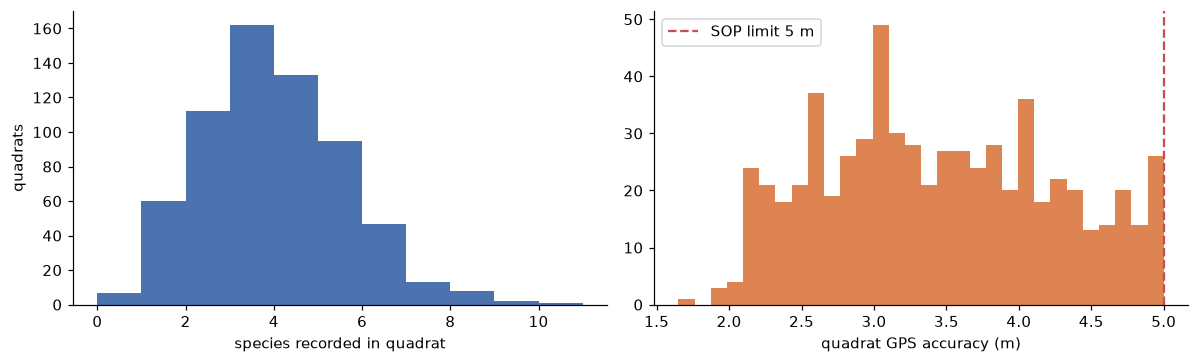

In [9]:
quad = quad_raw.rename(columns={
    "KEY": "quadrat_key", "PARENT_KEY": "submission_key", "herbs_present": "herbs_present",
    "herb_species-count_herb_species": "n_known_species", "species_list-all_species_list": "all_species_list",
    "herb_species-all_unknown_unidentifiable": "all_unknown",
    "location_quadrat-Latitude": "lat", "location_quadrat-Longitude": "lon",
    "location_quadrat-Accuracy": "gps_accuracy_m", "quadrat_comment": "comment"})
quad = quad.merge(survey[["submission_key", "plot_name", "review_state"]], on="submission_key", how="left")
quad["n_species_listed"] = quad["all_species_list"].fillna("").str.split("<br/>").apply(lambda l: len([x for x in l if x]))

display(quad["herbs_present"].value_counts(dropna=False).to_frame("quadrats"))
display(quad[["n_species_listed", "gps_accuracy_m"]].describe().T)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(quad["n_species_listed"], bins=range(0, quad["n_species_listed"].max() + 2), color="#4C72B0")
axes[0].set_xlabel("species recorded in quadrat"); axes[0].set_ylabel("quadrats")
axes[1].hist(quad["gps_accuracy_m"], bins=30, color="#DD8452")
axes[1].axvline(5, color="#C44E52", ls="--", label="SOP limit 5 m"); axes[1].legend()
axes[1].set_xlabel("quadrat GPS accuracy (m)")
fig.tight_layout(); fig.savefig(FIG / "B3_quadrat_eda.png")
quad.loc[quad["comment"].notna(), ["plot_name", "quadrat_number", "comment"]]

In [10]:
extra = extra_raw.rename(columns={"PARENT_KEY": "quadrat_key", "KEY": "entry_key"})
display(extra["species_entry_mode"].value_counts().to_frame("entries"))

# New free-text canonicals vs the existing species list: possible typos (flag later, never fix)
listed_names = species["label"].tolist()
new_names = extra.loc[extra["species_entry_mode"] == "new_missing", "new_missing_canonical"].dropna().unique()
typo_check = pd.DataFrame({"entered": new_names})
typo_check["has_trailing_or_double_space"] = typo_check["entered"].str.contains(r"^\s|\s$|\s{2,}")
typo_check["matches_Genus_species"] = typo_check["entered"].str.strip().str.fullmatch(r"[A-Z][a-z\-]+[ _][a-z\-]+")
typo_check["closest_in_species_list"] = typo_check["entered"].apply(
    lambda s: (difflib.get_close_matches(s.strip(), listed_names, n=1, cutoff=0.8) or [None])[0])
listed_genera = sorted(species["genus"].dropna().unique())
typo_check["genus_entered"] = typo_check["entered"].str.strip().str.split().str[0]
typo_check["genus_on_list"] = typo_check["genus_entered"].isin(listed_genera)
typo_check["closest_listed_genus"] = typo_check["genus_entered"].apply(
    lambda g: (difflib.get_close_matches(g, listed_genera, n=1, cutoff=0.8) or [None])[0])
typo_check.sort_values(["genus_on_list", "closest_listed_genus"], na_position="last")

,entries
species_entry_mode,
reuse_unknown,611
reuse_missing,578
new_unknown,62
new_missing,45


,entered,has_trailing_or_double_space,matches_Genus_species,closest_in_species_list,genus_entered,genus_on_list,closest_listed_genus
4,Ipomea leucanthemum,False,True,None,Ipomea,False,Ipomoea
17,Ipomea sinensis,False,True,None,Ipomea,False,Ipomoea
1,Cyperus margaritaceus,False,True,None,Cyperus,False,None
2,Zornia glochidiala,False,True,None,Zornia,False,None
5,Brachiara dura,False,True,None,Brachiara,False,None
6,Xenostegia pinnata,False,True,None,Xenostegia,False,None
7,Polygala erioptera,False,True,None,Polygala,False,None
18,Gisekia pharnaceoides,False,True,None,Gisekia,False,None
19,Erlangea misera,False,True,None,Erlangea,False,None
22,Abitulum ramosum,False,True,None,Abitulum,False,None


In [11]:
survey['include_in_analysis'] = survey['review_state'].ne('rejected')
remaining_duplicates = survey[survey['include_in_analysis']].duplicated(['survey_id','vegplot_id'], keep=False)
assert not remaining_duplicates.any(), 'Resolve duplicate non-rejected survey/plot submissions before pooling.'
display(survey[['plot_name','review_state','include_in_analysis']].sort_values('plot_name'))

,plot_name,review_state,include_in_analysis
15,SavMon_LW_Plot_01,NaN,True
13,SavMon_LW_Plot_02,NaN,True
28,SavMon_LW_Plot_03,NaN,True
8,SavMon_LW_Plot_04,NaN,True
23,SavMon_LW_Plot_05,NaN,True
18,SavMon_LW_Plot_06,NaN,True
9,SavMon_LW_Plot_07,NaN,True
31,SavMon_LW_Plot_08,NaN,True
24,SavMon_LW_Plot_09,NaN,True
26,SavMon_LW_Plot_10,NaN,True


## 4. Build a long species table without editing names

**Question:** Can we reproduce the species entries in the form?

**Why:** A long table supports incidence summaries, but missing values must not become species.

**Decision:** Preserve entered names, trace repeats to parent quadrats, and show derivation mismatches.

**Result:** The derived form-display list matches all 640 quadrats; canonical names remain as entered.

In [12]:
known = (quad[["submission_key", "quadrat_key", "plot_name", "quadrat_number", "herb_species-selected_herb_species_uuids"]]
         .assign(species_id=lambda d: d["herb_species-selected_herb_species_uuids"].str.split())
         .explode("species_id").dropna(subset=["species_id"])
         .merge(species[["__id", "label", "family"]].rename(columns={"__id": "species_id", "label": "species_name"}),
                on="species_id", how="left")
         .assign(source="species_list", entry_mode="list"))

name_by_mode = {"reuse_missing": "reused_missing_label", "new_missing": "new_missing_canonical",
                "reuse_unknown": "reused_unknown_label", "new_unknown": "auto_new_unknown_label"}
add = extra.merge(quad[["quadrat_key", "submission_key", "plot_name", "quadrat_number"]], on="quadrat_key", how="left")
add["species_name"] = [row[name_by_mode[m]] if m in name_by_mode else None
                       for m, row in zip(add["species_entry_mode"], add.to_dict("records"))]
add["source"] = np.where(add["species_entry_mode"].str.contains("unknown"), "unknown_morphospecies", "missing_from_list")
add = add.rename(columns={"species_entry_mode": "entry_mode"})

cols = ["submission_key", "plot_name", "quadrat_number", "quadrat_key", "species_name", "source", "entry_mode"]
obs = pd.concat([known[cols], add[cols + ["entry_key"]]], ignore_index=True)
# NOTE: species_name is kept exactly as entered (trailing spaces, typos). Do not normalise it here.
print(obs.shape)
display(obs["source"].value_counts().to_frame("rows"))
obs["form_display_name"] = obs["species_name"]
mask = obs["entry_key"].notna()
obs.loc[mask,"form_display_name"] = obs.loc[mask,"entry_key"].map(extra.set_index("entry_key")["validated_name"])

(2243, 8)


,rows
source,
species_list,947
unknown_morphospecies,673
missing_from_list,623


In [13]:
# Consistency: does the tidy table reproduce the form's own species list for each quadrat?
form_lists = quad.set_index("quadrat_key")["all_species_list"].fillna("").str.split("<br/>").apply(
    lambda l: sorted(x for x in l if x))
tidy_lists = obs.groupby("quadrat_key")["form_display_name"].apply(lambda s: sorted(str(x) for x in s.dropna() if str(x)))
cmp = pd.concat([form_lists.rename("form"), tidy_lists.rename("tidy")], axis=1)
cmp["tidy"] = cmp["tidy"].apply(lambda x: x if isinstance(x, list) else [])
cmp["match"] = cmp["form"] == cmp["tidy"]
print("quadrats where tidy == form list:", cmp["match"].mean().round(3))
cmp[~cmp["match"]].head(10)

quadrats where tidy == form list: 1.0


,form,tidy,match
quadrat_key,,,


In [14]:
obs['record_key'] = obs['entry_key'].fillna(obs['quadrat_key'].astype(str) + '/list/' + obs['species_name'].astype(str))
obs['include_in_analysis'] = obs['submission_key'].map(survey.set_index('submission_key')['include_in_analysis'])
obs['valid_name'] = obs['species_name'].notna() & obs['species_name'].astype(str).str.strip().ne('')
ecological_obs = obs[obs['include_in_analysis'] & obs['valid_name']].copy()
# No fuzzy corrections: these remain provisional taxa as entered, not verified taxonomic richness.
mismatches = cmp[~cmp['match']].copy()
display(mismatches)
mismatches.to_csv(OUT / 'vegetation_species_derivation_mismatches.csv')

,form,tidy,match
quadrat_key,,,


**Interpretation:** Null species names remain traceable issue rows but are excluded from species counts.
The form uses validated_name for display (for example herb_104 (Justicia divaricata )), while the ecological canonical is Justicia divaricata with its original trailing space. Both are retained. Remaining form-display mismatches are shown, not corrected;
review the actual mismatch table before calling the reconstruction equivalent. As-entered spelling variations
can inflate richness. Unknown morphospecies are retained within submissions and shown separately; their labels
are not automatically treated as globally comparable taxonomic identities across plots.

## 5. Measure transect geometry

**Question:** Do registered transects resemble the SOP design?

**Why:** The SOP requires a 50 m by 5 m belt and a midpoint within 25 m of its planned location.

**Decision:** Use metre distances, not degree differences; review rotations against obstacle or hazard exceptions and account for GPS uncertainty.

**Result:** Recorded lengths vary from the nominal 50 m; Plot 19 is about 22.65 m. Viable transect median bearing is about 104 degrees.

In [15]:
transects,cent_xy=build_transects(reg,centroids)
display(transects[['length_m','bearing_deg','midpoint_offset_m']].describe().round(1).T)

,count,mean,std,min,25%,50%,75%,max
length_m,30.0,49.1,9.3,22.6,44.9,49.0,55.5,65.6
bearing_deg,30.0,98.5,19.2,49.7,91.3,103.8,109.9,130.7
midpoint_offset_m,30.0,10.3,7.4,1.2,5.3,8.0,13.9,33.6


## 6. Generate traceable quality flags

**Question:** Which fields need review and why?

**Why:** A dashboard needs record-level findings rather than corrected raw values.

**Decision:** Separate SOP checks from analyst heuristics, and retain stable rule and record identifiers.

**Result:** One blank-name error, 23 stored-calculation discrepancies, and systematic orientation and spatial review findings are separated.

In [16]:
flags,rule_catalogue,QA,survey,transects,qgeom=build_flags(
    survey,quad,extra_raw,quad_raw,vegplots,obs,known,add,typo_check,listed_genera,
    reg,transects,recorder_in_team,q_per_sub,q_numbers_ok)
spatial_summary=spatial_rollup(qgeom,survey,QA)
rule_counts=flags.groupby(['rule_id','severity','level','message']).size().rename('n').reset_index()
display(rule_counts)
display(spatial_summary.sort_values('flagged_share',ascending=False).head(10))
calculation_audit=survey[['submission_key','plot_name','quadrats_with_species_declared','recomputed_quadrats_with_species','actual_quadrats_with_herbs']].copy()
calculation_audit['stored_minus_recomputed']=calculation_audit['quadrats_with_species_declared']-calculation_audit['recomputed_quadrats_with_species']
display(calculation_audit)
assert calculation_audit.recomputed_quadrats_with_species.eq(calculation_audit.actual_quadrats_with_herbs).all()
rule_catalogue.to_csv(OUT/'vegetation_rule_catalogue.csv',index=False)
spatial_summary.to_csv(OUT/'vegetation_spatial_rollup.csv',index=False)
calculation_audit.to_csv(OUT/'vegetation_form_calculation_audit.csv',index=False)
(OUT/'vegetation_qa_parameters.json').write_text(json.dumps(QA,indent=2))
viable=transects[transects.is_viable=='yes']
project_patterns=pd.DataFrame([
    {'finding':'Orientation departs from north-south','affected_records':int((viable.ns_deviation_deg>QA['bearing_tolerance_deg']).sum()),'denominator':len(viable),'severity':'warning','interpretation':'Systematic deviation; confirm field layout or capture issue.'},
    {'finding':'Device offset differs from expected EAT','affected_records':int(survey.start_offset.ne(QA['expected_tz_offset']).sum()),'denominator':len(survey),'severity':'info','interpretation':'Offset alone does not prove an incorrect clock.'},
    {'finding':'Stored calculation differs from repeat reconstruction','affected_records':int(calculation_audit.stored_minus_recomputed.ne(0).sum()),'denominator':len(survey),'severity':'warning','interpretation':'Cause may be calculation, form version, editing, or export; unresolved.'}])
display(project_patterns)
project_patterns.to_csv(OUT/'vegetation_project_patterns.csv',index=False)

,rule_id,severity,level,message,n
0,P01,warning,plot,Measured endpoint length outside analyst tolerance 45-55 m; review GPS,16
1,P02,warning,plot,Transect departs from north-south; confirm obstacle or hazard justification,30
2,P03,warning,plot,Measured midpoint >25 m from planned centroid; review GPS uncertainty,1
3,Q04,warning,quadrat,Quadrat outside transect belt plus quadrat accuracy and 5m endpoint allowanc...,127
4,S01,warning,survey,More than one submission for this survey and plot; retain review status,4
5,S02,warning,survey,Submission marked rejected in ODK review,2
6,S05,info,survey,Device time-zone offset is not EAT (+03:00); check device clock,32
7,SP00,error,species,Species entry has no name,1
8,SP01,warning,species,Species name has leading/trailing/double spaces,66
9,SP02,info,species,Free-text name is close to a name on the species list; review (often a diffe...,3


,submission_key,plot_name,quadrats,flagged_quadrats,median_distance_m,flagged_beyond_endpoint,flagged_share,include_in_analysis
8,uuid:5d242bf2-8888-4eb0-9082-431482177425,SavMon_LW_Plot_05,20,19,22.073348,6,0.95,True
23,uuid:c803a008-7014-4a4e-a485-68e1d90d767c,SavMon_LW_Plot_27,20,12,14.034256,7,0.60,True
29,uuid:ebe93f04-c927-4af3-9668-21b6540c01ea,SavMon_LW_Plot_13,20,11,11.471838,0,0.55,True
4,uuid:430e85a3-44ce-45f4-9974-c6a61569e78b,SavMon_LW_Plot_07,20,9,10.244804,1,0.45,True
16,uuid:9ec95900-d4e8-4825-be75-07834b98cc6c,SavMon_LW_Plot_19,20,9,8.214685,5,0.45,True
31,uuid:fdf5f121-0a7f-4769-85bb-4717e0361eb4,SavMon_LW_Plot_14,20,7,8.733194,2,0.35,True
9,uuid:7ae61d55-3663-422e-aad2-9104b56c9a47,SavMon_LW_Plot_06,20,6,5.468545,0,0.30,True
1,uuid:359a5da6-d237-4203-b838-8596bdbd4935,SavMon_LW_Plot_08,20,6,7.380967,1,0.30,True
3,uuid:4137458f-31e5-4355-b4ad-47858fb11503,SavMon_LW_Plot_04,20,5,4.318467,1,0.25,True
17,uuid:9fd08bb2-7c3f-49f5-8ad8-dd6f45da94da,SavMon_LW_Plot_01,20,5,9.801915,1,0.25,True


,submission_key,plot_name,quadrats_with_species_declared,recomputed_quadrats_with_species,actual_quadrats_with_herbs,stored_minus_recomputed
0,uuid:599e04cf-832f-4535-8305-967918d12026,SavMon_LW_Plot_16,19,20,20,-1
1,uuid:c6cc7231-7af6-4bc5-b281-565c53f21763,SavMon_LW_Plot_21,18,20,20,-2
2,uuid:49d73df9-2d36-4a1e-aa29-6f94f23a7513,SavMon_LW_Plot_21,19,20,20,-1
3,uuid:cf362fbc-991a-4db1-8d49-6c1d29fd49c8,SavMon_LW_Plot_18,20,20,20,0
4,uuid:9e1251bb-84c1-4b7a-a8bb-bafcf7afc82c,SavMon_LW_Plot_11,20,20,20,0
5,uuid:81e3bc36-700f-465d-a1aa-48ebed04a78c,SavMon_LW_Plot_18,20,20,20,0
6,uuid:938c15e5-c942-49aa-8e6d-9633189870ff,SavMon_LW_Plot_29,19,20,20,-1
7,uuid:8e5f5c9d-d697-4358-b766-db4a41f28c3e,SavMon_LW_Plot_25,19,20,20,-1
8,uuid:4137458f-31e5-4355-b4ad-47858fb11503,SavMon_LW_Plot_04,18,19,19,-1
9,uuid:430e85a3-44ce-45f4-9974-c6a61569e78b,SavMon_LW_Plot_07,17,20,20,-3


,finding,affected_records,denominator,severity,interpretation
0,Orientation departs from north-south,30,30,warning,Systematic deviation; confirm field layout or capture issue.
1,Device offset differs from expected EAT,32,32,info,Offset alone does not prove an incorrect clock.
2,Stored calculation differs from repeat reconstruction,23,32,warning,"Cause may be calculation, form version, editing, or export; unresolved."


**Interpretation:** Stored calculation discrepancies are warnings about derived data, with cause unresolved. All 30 viable transects depart from the north–south review tolerance; the median bearing is about 104 degrees. This systematic pattern is a project-level finding and the underlying plot flags remain available. Rotation is permitted for obstacles or hazards, but this dataset alone does not establish the reason.

Plot 05 has 19 of 20 quadrats outside the registered belt plus the configured GPS allowance, with a median distance of about 22 m. This is a strong review signal, not proof of the cause. Geometry uses distance to a finite segment, so some flags are beyond recorded endpoints. A +02:00 device offset is retained and is not automatically corrected. Empty quadrats and blank optional comments are legitimate.

## 7. Survey-level summary

**Question:** How much valid effort was recorded, and what issues need review?

**Why:** The report needs clear denominators for all records and analysis-eligible records.

**Decision:** QA covers all submissions. Ecological results use non-rejected submissions and valid nonblank names.

**Result:** QA includes all 32 submissions; analysis uses 30. Project patterns and issue counts have explicit denominators.

In [17]:
eligible = survey[survey['include_in_analysis']]
eligible_quad = quad[quad['submission_key'].isin(eligible['submission_key'])]
survey_summary = pd.Series({
    'project':survey['survey_begin-project_label'].iloc[0],
    'area':survey['survey_begin-area_label'].iloc[0],
    'all_submissions':len(survey),'analysis_submissions':len(eligible),
    'rejected_submissions':int(survey['review_state'].eq('rejected').sum()),
    'primary_planned_locations':int(centroids['sample_status'].eq('primary').sum()),
    'registered_viable':int(reg['is_viable'].eq('yes').sum()),
    'registered_nonviable':int(reg['is_viable'].eq('no').sum()),
    'all_surveyed_plots':survey['vegplot_id'].nunique(),'analysis_plots':eligible['vegplot_id'].nunique(),
    'all_quadrat_rows':len(quad),'analysis_quadrat_rows':len(eligible_quad),
    'analysis_quadrats_with_herbs':int(eligible_quad['herbs_present'].eq('yes').sum()),
    'as_entered_named_taxa_including_unknowns':ecological_obs['species_name'].nunique(),
    'unknown_labels_within_analysis':ecological_obs.loc[ecological_obs['source']=='unknown_morphospecies','species_name'].nunique(),
    'flags_errors':int(flags['severity'].eq('error').sum()),
    'flags_warnings':int(flags['severity'].eq('warning').sum()),
    'flags_info':int(flags['severity'].eq('info').sum()),
},name='value').to_frame()
display(survey_summary)

,value
project,Savanna Monitoring Pilot
area,LW
all_submissions,32
analysis_submissions,30
rejected_submissions,2
primary_planned_locations,36
registered_viable,30
registered_nonviable,1
all_surveyed_plots,30
analysis_plots,30


## 8. Plot-level summary

**Question:** How does quality and provisional richness differ between submissions?

**Why:** Repeated or rejected submissions must be visible rather than merged away.

**Decision:** One row per submission, with its plot UUID, status, effort, provisional richness and quality counts.

**Result:** Plot 05 has 19 of 20 quadrats flagged and a median segment distance of about 22 m; submission-level roll-ups preserve drill-down.

In [18]:
flag_counts = flags[flags['submission_key'].notna()].groupby(['submission_key','severity']).size().unstack(fill_value=0)
rich = ecological_obs.groupby('submission_key')['species_name'].nunique().rename('provisional_richness')
plot_summary = survey[['submission_key','vegplot_id','plot_name','review_state','include_in_analysis','duration_min','actual_quadrats','actual_quadrats_with_herbs']].copy()
plot_summary = plot_summary.merge(rich,on='submission_key',how='left',validate='one_to_one')
plot_summary = plot_summary.merge(flag_counts,left_on='submission_key',right_index=True,how='left',validate='one_to_one')
plot_flags = flags[flags['level']=='plot'].groupby('plot_name').size().rename('registration_flags')
plot_summary = plot_summary.merge(plot_flags,on='plot_name',how='left',validate='many_to_one')
for c in ['error','warning','info','registration_flags']:
    if c not in plot_summary: plot_summary[c]=0
    plot_summary[c]=plot_summary[c].fillna(0).astype(int)
plot_summary.loc[plot_summary['include_in_analysis'] & plot_summary['provisional_richness'].isna(),'provisional_richness']=0
display(plot_summary.sort_values('plot_name'))
display(flags[flags['rule_id'].isin(['SP05','SP00','P01'])][['rule_id','plot_name','field','value','message']].head(20))
plot_summary=plot_summary.merge(spatial_summary[['submission_key','flagged_quadrats','flagged_share','median_distance_m','flagged_beyond_endpoint']],on='submission_key',how='left',validate='one_to_one')
display(plot_summary[['plot_name','review_state','provisional_richness','flagged_quadrats','flagged_share','median_distance_m']].sort_values('flagged_share',ascending=False))

,submission_key,vegplot_id,plot_name,review_state,include_in_analysis,duration_min,actual_quadrats,actual_quadrats_with_herbs,provisional_richness,error,info,warning,registration_flags
15,uuid:9fd08bb2-7c3f-49f5-8ad8-dd6f45da94da,5e003c10-72d4-42a4-9af5-6dbfbeac222c,SavMon_LW_Plot_01,NaN,True,69.574417,20,20,32.0,0,1,14,2
13,uuid:e63b6ad6-7893-4cca-a1db-00fbde18a2aa,51769cf3-e211-448e-9e29-605c1be4ed5b,SavMon_LW_Plot_02,NaN,True,100.315317,20,19,19.0,0,1,2,1
28,uuid:967cb42c-f21a-4ba6-92be-81cd6d2b0e8d,26e5a11d-9c38-4c69-9919-aa8489756096,SavMon_LW_Plot_03,NaN,True,58.678800,20,18,15.0,0,1,3,2
8,uuid:4137458f-31e5-4355-b4ad-47858fb11503,3b4fc821-0b06-4e19-b17b-1330d0dbaf90,SavMon_LW_Plot_04,NaN,True,56.388500,20,19,20.0,0,1,6,1
23,uuid:5d242bf2-8888-4eb0-9082-431482177425,dbd003da-4c6a-46a3-95be-ce6febaaab89,SavMon_LW_Plot_05,NaN,True,102.489867,20,19,17.0,0,1,21,1
18,uuid:7ae61d55-3663-422e-aad2-9104b56c9a47,f3fb5ba5-0209-4ac4-9666-8023f28a8918,SavMon_LW_Plot_06,NaN,True,91.817417,20,20,26.0,0,2,6,1
9,uuid:430e85a3-44ce-45f4-9974-c6a61569e78b,5aafaaed-0656-401d-aea7-3b18bf206c7f,SavMon_LW_Plot_07,NaN,True,56.491017,20,20,18.0,0,1,10,1
31,uuid:359a5da6-d237-4203-b838-8596bdbd4935,edf62d32-bf13-47ec-ad1c-356bed17570a,SavMon_LW_Plot_08,NaN,True,235.968850,20,20,31.0,0,1,8,1
24,uuid:95cde0b4-8b49-4f5d-a3c7-6765e1c06466,3aac9518-a602-45ce-995c-cc06fc17975a,SavMon_LW_Plot_09,NaN,True,81.733700,20,20,29.0,0,1,9,1
26,uuid:3865525f-1d45-40fc-83ca-7e30fafe6b54,d17cbd2e-4c3a-4a01-bd96-59b63764c5d5,SavMon_LW_Plot_10,NaN,True,63.200233,20,20,21.0,0,1,3,2


,rule_id,plot_name,field,value,message
107,SP00,SavMon_LW_Plot_28,species_name,reuse_missing,Species entry has no name
110,SP05,SavMon_LW_Plot_16,quadrats_with_species_declared,19,Stored form calculation differs from recomputation from repeat records
111,SP05,SavMon_LW_Plot_21,quadrats_with_species_declared,18,Stored form calculation differs from recomputation from repeat records
112,SP05,SavMon_LW_Plot_21,quadrats_with_species_declared,19,Stored form calculation differs from recomputation from repeat records
113,SP05,SavMon_LW_Plot_29,quadrats_with_species_declared,19,Stored form calculation differs from recomputation from repeat records
114,SP05,SavMon_LW_Plot_25,quadrats_with_species_declared,19,Stored form calculation differs from recomputation from repeat records
115,SP05,SavMon_LW_Plot_04,quadrats_with_species_declared,18,Stored form calculation differs from recomputation from repeat records
116,SP05,SavMon_LW_Plot_07,quadrats_with_species_declared,17,Stored form calculation differs from recomputation from repeat records
117,SP05,SavMon_LW_Plot_15,quadrats_with_species_declared,17,Stored form calculation differs from recomputation from repeat records
118,SP05,SavMon_LW_Plot_20,quadrats_with_species_declared,19,Stored form calculation differs from recomputation from repeat records


,plot_name,review_state,provisional_richness,flagged_quadrats,flagged_share,median_distance_m
23,SavMon_LW_Plot_05,NaN,17.0,19,0.95,22.073348
21,SavMon_LW_Plot_27,NaN,22.0,12,0.60,14.034256
16,SavMon_LW_Plot_13,NaN,12.0,11,0.55,11.471838
9,SavMon_LW_Plot_07,NaN,18.0,9,0.45,10.244804
20,SavMon_LW_Plot_19,NaN,19.0,9,0.45,8.214685
25,SavMon_LW_Plot_14,NaN,19.0,7,0.35,8.733194
18,SavMon_LW_Plot_06,NaN,26.0,6,0.30,5.468545
31,SavMon_LW_Plot_08,NaN,31.0,6,0.30,7.380967
15,SavMon_LW_Plot_01,NaN,32.0,5,0.25,9.801915
8,SavMon_LW_Plot_04,NaN,20.0,5,0.25,4.318467


## 9. Assess actual sampling effort

**Question:** Does the observed richness curve flatten, and where is effort incomplete?

**Why:** A completed form does not guarantee adequate ecological coverage.

**Decision:** Use only actual sampled quadrats, including genuinely empty ones. Do not invent missing quadrats or declare adequacy from a fixed cutoff.

**Result:** Actual quadrat effort is complete; 29 of 36 primary locations are surveyed and several curves still accumulate taxa.

,submission_key,actual_quadrats,richness_final,expected_new_taxa_in_final_up_to_5_quadrats,effort_status,ecological_adequacy,plot_name
26,uuid:e7de35f0-a715-47f1-885f-fd5a0d9a2907,20,40.0,5.720,complete_protocol_effort,not_established_from_single_survey,SavMon_LW_Plot_12
1,uuid:359a5da6-d237-4203-b838-8596bdbd4935,20,31.0,4.455,complete_protocol_effort,not_established_from_single_survey,SavMon_LW_Plot_08
16,uuid:9fd08bb2-7c3f-49f5-8ad8-dd6f45da94da,20,32.0,4.275,complete_protocol_effort,not_established_from_single_survey,SavMon_LW_Plot_01
12,uuid:95cde0b4-8b49-4f5d-a3c7-6765e1c06466,20,29.0,4.175,complete_protocol_effort,not_established_from_single_survey,SavMon_LW_Plot_09
6,uuid:54452130-d92e-4996-a0d7-9401811b9ed7,20,22.0,4.020,complete_protocol_effort,not_established_from_single_survey,SavMon_LW_Plot_15
23,uuid:cf362fbc-991a-4db1-8d49-6c1d29fd49c8,20,28.0,4.005,complete_protocol_effort,not_established_from_single_survey,SavMon_LW_Plot_18
20,uuid:c4ea3469-7e1c-474a-9ce6-fc1926e590e2,20,22.0,3.650,complete_protocol_effort,not_established_from_single_survey,SavMon_LW_Plot_28
9,uuid:7ae61d55-3663-422e-aad2-9104b56c9a47,20,26.0,3.490,complete_protocol_effort,not_established_from_single_survey,SavMon_LW_Plot_06
10,uuid:8e5f5c9d-d697-4358-b766-db4a41f28c3e,20,31.0,3.405,complete_protocol_effort,not_established_from_single_survey,SavMon_LW_Plot_25
19,uuid:c17516f9-53dd-4fda-b4e6-e257068198b9,20,25.0,3.275,complete_protocol_effort,not_established_from_single_survey,SavMon_LW_Plot_30


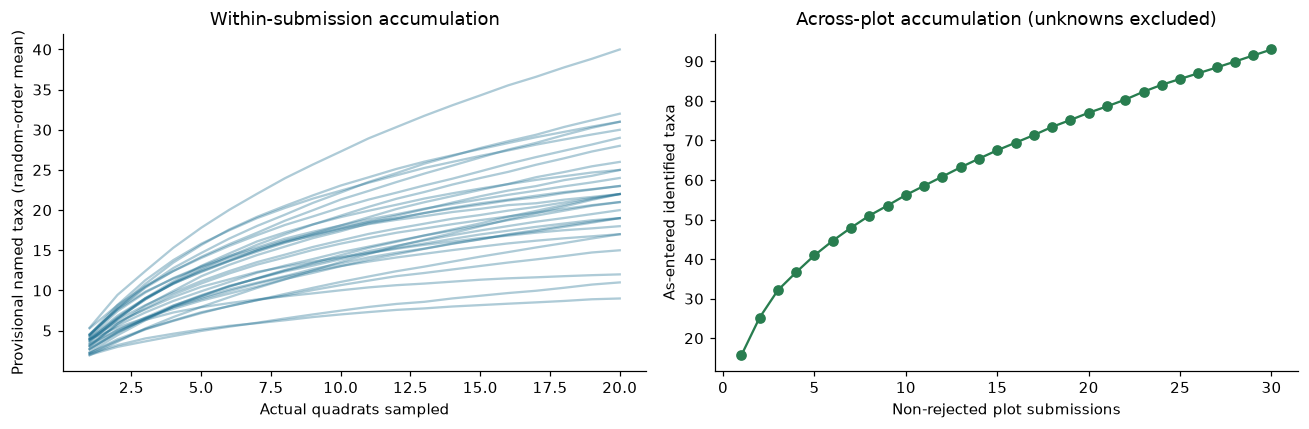

,plot_name,actual_quadrats,expected_new_taxa_in_final_up_to_5_quadrats,tail_share_of_observed_richness,effort_interpretation
6,SavMon_LW_Plot_15,20,4.020,0.182727,continued taxa accumulation; prioritize sampling review
20,SavMon_LW_Plot_28,20,3.650,0.165909,continued taxa accumulation; prioritize sampling review
8,SavMon_LW_Plot_05,20,2.795,0.164412,continued taxa accumulation; prioritize sampling review
28,SavMon_LW_Plot_24,20,1.660,0.150909,continued taxa accumulation; prioritize sampling review
12,SavMon_LW_Plot_09,20,4.175,0.143966,continued taxa accumulation; prioritize sampling review
1,SavMon_LW_Plot_08,20,4.455,0.143710,continued taxa accumulation; prioritize sampling review
23,SavMon_LW_Plot_18,20,4.005,0.143036,continued taxa accumulation; prioritize sampling review
26,SavMon_LW_Plot_12,20,5.720,0.143000,continued taxa accumulation; prioritize sampling review
29,SavMon_LW_Plot_14,20,2.650,0.139474,continued taxa accumulation; prioritize sampling review
2,SavMon_LW_Plot_10,20,2.920,0.139048,continued taxa accumulation; prioritize sampling review


,plot_name,sample_status,is_viable,n_submissions
16,SavMon_LW_Plot_23,primary,no,0.0
40,SavMon_LW_Plot_31,primary,NaN,0.0
41,SavMon_LW_Plot_32,primary,NaN,0.0
42,SavMon_LW_Plot_33,primary,NaN,0.0
43,SavMon_LW_Plot_34,primary,NaN,0.0
44,SavMon_LW_Plot_35,primary,NaN,0.0
45,SavMon_LW_Plot_36,primary,NaN,0.0


Primary locations surveyed: 29 of 36


In [19]:
species_by_quad = ecological_obs.groupby('quadrat_key')['species_name'].apply(set).to_dict()
effort_rows = []; plot_curves={}
for sub, d in eligible_quad.groupby('submission_key'):
    groups = [species_by_quad.get(k,set()) for k in d['quadrat_key']]
    curve = accumulation(groups)
    plot_curves[sub]=curve
    tail = curve[-1]-curve[max(0,len(curve)-6)]
    effort_rows.append({'submission_key':sub,'actual_quadrats':len(groups),'richness_final':curve[-1],
                        'expected_new_taxa_in_final_up_to_5_quadrats':tail,
                        'effort_status':'complete_protocol_effort' if len(groups)==QA['expected_quadrats'] else 'incomplete_protocol_effort',
                        'ecological_adequacy':'not_established_from_single_survey'})
effort = pd.DataFrame(effort_rows).merge(survey[['submission_key','plot_name']],on='submission_key',validate='one_to_one')
display(effort.sort_values('expected_new_taxa_in_final_up_to_5_quadrats',ascending=False))
# Cross-plot curves exclude provisional unknown labels to avoid merging unlike unidentified taxa.
identified = ecological_obs[ecological_obs['source']!='unknown_morphospecies']
identified_sets = identified.groupby('submission_key')['species_name'].apply(set).to_dict()
project_sets = [identified_sets.get(k,set()) for k in eligible['submission_key']]
project_curve = accumulation(project_sets)
fig, axes = plt.subplots(1,2,figsize=(12,4))
for curve in plot_curves.values(): axes[0].plot(range(1,len(curve)+1),curve,alpha=.35,color='#186b8e')
axes[0].set(xlabel='Actual quadrats sampled',ylabel='Provisional named taxa (random-order mean)',title='Within-submission accumulation')
axes[1].plot(range(1,len(project_curve)+1),project_curve,marker='o',color='#287d4f')
axes[1].set(xlabel='Non-rejected plot submissions',ylabel='As-entered identified taxa',title='Across-plot accumulation (unknowns excluded)')
fig.tight_layout(); fig.savefig(FIG / 'B9_sampling_effort.png'); plt.show()
# Tail categories are review priorities, not declarations of ecological adequacy.
effort['tail_share_of_observed_richness']=effort['expected_new_taxa_in_final_up_to_5_quadrats']/effort['richness_final'].replace(0,np.nan)
effort['effort_interpretation']=np.select(
    [effort.actual_quadrats!=QA['expected_quadrats'], effort.tail_share_of_observed_richness>=.10],
    ['incomplete protocol effort','continued taxa accumulation; prioritize sampling review'],
    default='smaller tail; adequacy remains unverified')
display(effort[['plot_name','actual_quadrats','expected_new_taxa_in_final_up_to_5_quadrats','tail_share_of_observed_richness','effort_interpretation']].sort_values('tail_share_of_observed_richness',ascending=False))
coverage_assessment=coverage[['plot_name','sample_status','is_viable','n_submissions']].copy()
missing_primary=coverage_assessment[(coverage_assessment.sample_status=='primary') & (coverage_assessment.n_submissions==0)]
display(missing_primary)
print('Primary locations surveyed:',int(((coverage.sample_status=='primary') & (coverage.n_submissions>0)).sum()),'of',int((coverage.sample_status=='primary').sum()))


**Assessment:** All 30 non-rejected submissions contain the prescribed 20 actual quadrats. This establishes protocol effort, not ecological completeness. Twenty-nine of 36 primary locations were surveyed. Plot 23 was registered non-viable, backup Plot 46 was surveyed, and no supplied replacement crosswalk confirms the relationship. Primaries 31–36 have no registration or survey in the supplied exports and cluster to the north-east, indicating incomplete spatial coverage in this dataset.

Plot 12 adds about 5.7 taxa in its final five quadrats on the random-order mean curve; Plots 08, 01, 09 and 15 also add more than four. The 10% tail-share category is an analyst prioritisation heuristic. A smaller tail does not prove adequate sampling. Unknown labels and as-entered spelling variations keep richness provisional; seasons and habitats require a broader sampling design.

## 10. Map the transects and preserve spatial outputs

**Question:** Where are planned plots, registered transects and flagged locations?

**Why:** Maps make coverage gaps and unusual geometry easier to review.

**Decision:** Export an interactive review map (`src/transect_map.py`), a static overview and GeoJSON; no inferred coordinate corrections. Transect colour shows spatial review priority from existing QA flags, always with an icon and label.

**Result:** Three transects are critical (half or more quadrats off the registered line: Plots 05, 27 and 13), seven serious, 17 warning and three without spatial flags. Planned primaries without a registration and the non-viable Plot 23 are marked separately; GeoJSON is written once.

In [20]:
from src.transect_map import build_transect_map

center = [transects["m_lat"].mean(), transects["m_lon"].mean()]
flagged_plots = set(flags.loc[flags["severity"].isin(["error", "warning"]), "plot_name"])
mapped = transects.dropna(subset=["a_lat", "m_lat", "b_lat"])
print("transects without coordinates:", sorted(set(transects["plot_name"]) - set(mapped["plot_name"])))

fmap = build_transect_map(transects, qgeom, centroids, coverage, flags, survey,
                          plot_summary, effort, QA, areas=pd.read_csv(RAW / "areas.csv"))
fmap.save(OUT / "transect_map.html")
fmap

transects without coordinates: ['SavMon_LW_Plot_23']


- Static overview for the Markdown report. Transects are 50 m long and the area spans ~17 km, so lines would be
- invisible here: show each planned location by status; the interactive map (above) shows the transect lines.

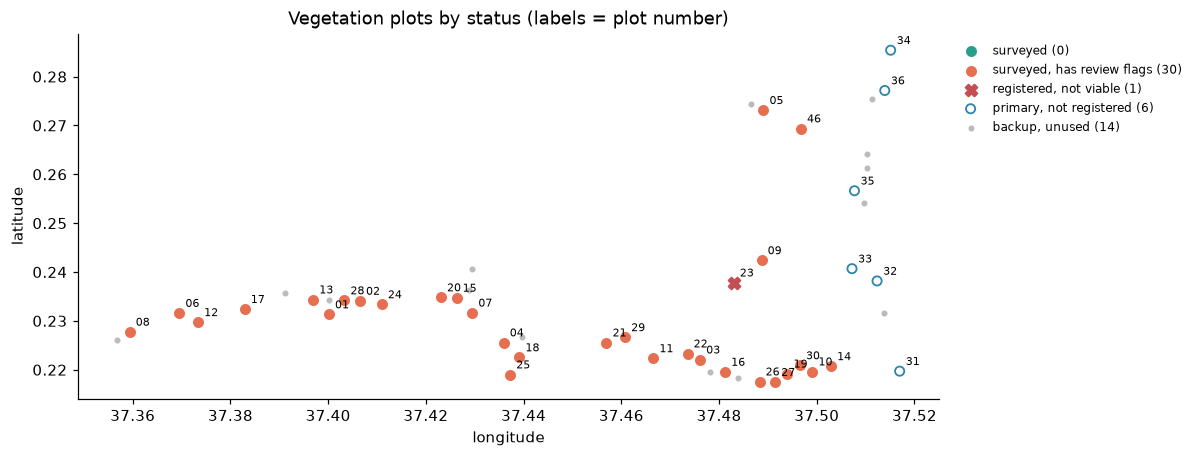

In [21]:

status_style = {
    "surveyed": dict(color="#2A9D8F", marker="o", s=36),
    "surveyed, has review flags": dict(color="#E76F51", marker="o", s=36),
    "registered, not viable": dict(color="#C44E52", marker="X", s=60),
    "primary, not registered": dict(color="#2E86AB", marker="o", s=36, facecolors="none"),
    "backup, unused": dict(color="#BBBBBB", marker=".", s=30),
}
cov = coverage.copy()
cov[["lat", "lon"]] = cov["centroid_id"].map(cent_xy).apply(pd.Series).values
cov["status"] = np.select(
    [(cov["n_submissions"] > 0) & cov["plot_name"].isin(flagged_plots), cov["n_submissions"] > 0,
     cov["is_viable"] == "no", cov["sample_status"] == "primary"],
    ["surveyed, has review flags", "surveyed", "registered, not viable", "primary, not registered"],
    default="backup, unused")

span_lon, span_lat = cov["lon"].max() - cov["lon"].min(), cov["lat"].max() - cov["lat"].min()
fig, ax = plt.subplots(figsize=(11, max(3.5, 11 * span_lat / span_lon) + 1))
for status, style in status_style.items():
    d = cov[cov["status"] == status]
    kw = dict(style)
    face = kw.pop("facecolors", None)
    ax.scatter(d["lon"], d["lat"], label=f"{status} ({len(d)})", edgecolors=kw["color"],
               facecolors=face if face else kw["color"], marker=kw["marker"], s=kw["s"], linewidths=1.2)
for _, r in cov[cov["status"] != "backup, unused"].iterrows():
    ax.annotate(r["plot_name"].split("_")[-1], (r["lon"], r["lat"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_aspect(1 / np.cos(np.radians(center[0])))
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Vegetation plots by status (labels = plot number)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(FIG / "B9_transect_map.png", bbox_inches="tight")



In [22]:
features=[]
for _, t in mapped.iterrows():
    features.append({'type':'Feature','geometry':{'type':'LineString','coordinates':[[float(t['a_lon']),float(t['a_lat'])],[float(t['m_lon']),float(t['m_lat'])],[float(t['b_lon']),float(t['b_lat'])]]},
                     'properties':{'plot_name':t['plot_name'],'is_viable':t['is_viable'],'length_m':float(t['length_m']),'midpoint_offset_m':float(t['midpoint_offset_m'])}})
(OUT / 'transects.geojson').write_text(json.dumps({'type':'FeatureCollection','features':features},indent=2,allow_nan=False))
print('Map tiles need internet; coordinates and GeoJSON are retained independently.')

Map tiles need internet; coordinates and GeoJSON are retained independently.


## 11. Export evidence for the report and implementation contract

**Question:** How can the Tech team automate these checks?

**Why:** They need schemas, rule parameters, identifiers, and inclusion policy.

**Decision:** Separate immutable raw data, derived staging, flags and analytical summaries; version the rules.

**Result:** Traceable flags, rule catalogue, roll-ups, summaries and JSON evidence regenerate; authored reports remain untouched.

In [23]:
flags.to_csv(OUT/'veg_qa_flags.csv',index=False)
survey_summary.to_csv(OUT/'veg_survey_summary.csv')
plot_summary.to_csv(OUT/'veg_plot_summary.csv',index=False)
effort.to_csv(OUT/'veg_sampling_effort.csv',index=False)
obs.to_csv(OUT/'veg_observations_long.csv',index=False)
transects.to_csv(OUT/'vegetation_transect_geometry.csv',index=False)
coverage.to_csv(OUT/'vegetation_plot_coverage.csv',index=False)
assert len(survey)==len(survey_raw) and len(quad)==len(quad_raw)
assert len(plot_summary)==len(survey)
assert flags.flag_id.is_unique and flags.record_key.notna().all()
assert len(eligible_quad)==int(effort.actual_quadrats.sum())
assert flags.loc[flags.rule_id=='SP05','severity'].eq('warning').all()
verify_raw_unchanged(RAW,INPUT_HASHES)
save_evidence(OUT/'vegetation_findings.json',{
    'all_submissions':len(survey),'analysis_submissions':len(eligible),'actual_analysis_quadrats':len(eligible_quad),
    'species_display_reconstruction_matches':int(cmp['match'].sum()),'species_display_reconstruction_total':len(cmp),
    'error_flags':int(flags.severity.eq('error').sum()),'warning_flags':int(flags.severity.eq('warning').sum()),'info_flags':int(flags.severity.eq('info').sum()),
    'stored_calculation_discrepancies':int(calculation_audit.stored_minus_recomputed.ne(0).sum()),
    'orientation_records':len(viable),'orientation_median_bearing':float(viable.bearing_deg.median()),
    'primary_surveyed':int(((coverage.sample_status=='primary') & (coverage.n_submissions>0)).sum()),
    'primary_planned':int(coverage.sample_status.eq('primary').sum())})
print('Evidence exported. Authored reports in reports/ were preserved.')

Original input bytes preserved.
Evidence exported. Authored reports in reports/ were preserved.


## 12. Build the results dashboard

**Question:** How can reviewers read the results and fetch any output without running Python?

**Why:** Natural State staff need the decisions, the evidence and the files in one place they can open offline.

**Decision:** Build a static four-page dashboard (overview, birds, vegetation, files) from the exported files only; it adds no analysis. **Run notebook 01 first**: the bird page reads its outputs and shows a notice when they are missing.

**Result:** `outputs/dashboard/index.html` opens straight from disk; **Files** previews and downloads every output.

In [24]:
from src.dashboard import build_dashboard
build_dashboard(ROOT)

[WindowsPath('D:/Natural State/natural-state-take-home/natural-state-take-home/outputs/dashboard/index.html'),
 WindowsPath('D:/Natural State/natural-state-take-home/natural-state-take-home/outputs/dashboard/birds.html'),
 WindowsPath('D:/Natural State/natural-state-take-home/natural-state-take-home/outputs/dashboard/vegetation.html'),
 WindowsPath('D:/Natural State/natural-state-take-home/natural-state-take-home/outputs/dashboard/files.html')]